# Рекуррентный график цены биткоина

Ноутбук заново собирает график из старого `Fractal.ipynb`: заголовок **Recurrence Graph of Bitcoin Price Patterns**.

Берётся код той ячейки, а не картинка из поста. Параметры те же:

- ряд: `log(Close)`
- `RecurrencePlot(threshold="point", percentage=3, dimension=1)`
- цена белым поверх графика, ось цены логарифмическая
- вертикальные линии халвингов: 2012-11-28, 2016-07-09, 2020-05-11, 2024-04-20

Данные качает первая ячейка старого ноутбука: `BTC-USD` с Yahoo Finance, `2010-01-01` — `2025-08-22`. У Yahoo дневная история начинается с 2014-09-17. Ячейка `pd.read_csv("../data/BTC_1d.csv")` из старого файла сюда не перенесена: самого csv в ноутбуке нет.

Из ячейки с графиком убрано то, что на рисунок не попадало и мешало запуску: цикл показателя Херста (функция `hurst_exponent` в той ячейке не определена, линии на графике нет) и пустая нижняя панель `GridSpec`.

Запуск: **Run All**. Файл графика: `output/bitcoin_recurrence_price_plot.png`.


## Данные


In [1]:
from datetime import datetime
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf
from matplotlib.gridspec import GridSpec
from pyts.image import RecurrencePlot

ticker = "BTC-USD"
start_date = "2010-01-01"
end_date = "2025-08-22"

btc_df = yf.download(ticker, start=start_date, end=end_date, progress=False)

# Сейчас yfinance возвращает колонки с двумя уровнями: (поле, тикер).
# В старом ноутбуке столбцы были плоскими, дальше используется Close.
if isinstance(btc_df.columns, pd.MultiIndex):
    btc_df.columns = btc_df.columns.get_level_values(0)

btc_df.index = pd.to_datetime(btc_df.index)
btc_df.index.name = "Date"
btc_data = btc_df.copy()

print(
    f"{btc_data.index.min().date()} — {btc_data.index.max().date()}, "
    f"строк: {len(btc_data)}"
)
btc_data[["Open", "High", "Low", "Close", "Volume"]].tail()


2014-09-17 — 2025-08-21, строк: 3992


Price,Open,High,Low,Close,Volume
Date,,,,,
2025-08-17,117492.789062,118595.773438,117279.523438,117453.062500,45852169525
2025-08-18,117453.906250,117614.171875,114723.679688,116252.312500,72787808090
2025-08-19,116241.859375,116764.500000,112730.398438,112831.179688,71657600353
2025-08-20,112828.023438,114625.796875,112387.960938,114274.742188,67993811526
2025-08-21,114275.687500,114802.648438,111986.234375,112419.031250,57817883700


## График

Яркая точка значит, что логарифмы цены в эти два дня близки: порог выбран так, чтобы близкими были 3% пар дней. Диагональ — день сам с собой. Жёлтые блоки — участки, где цена долго оставалась в одном диапазоне. Белая линия — сама цена. Красный пунктир — халвинг.


/workspace/output/bitcoin_recurrence_price_plot.png


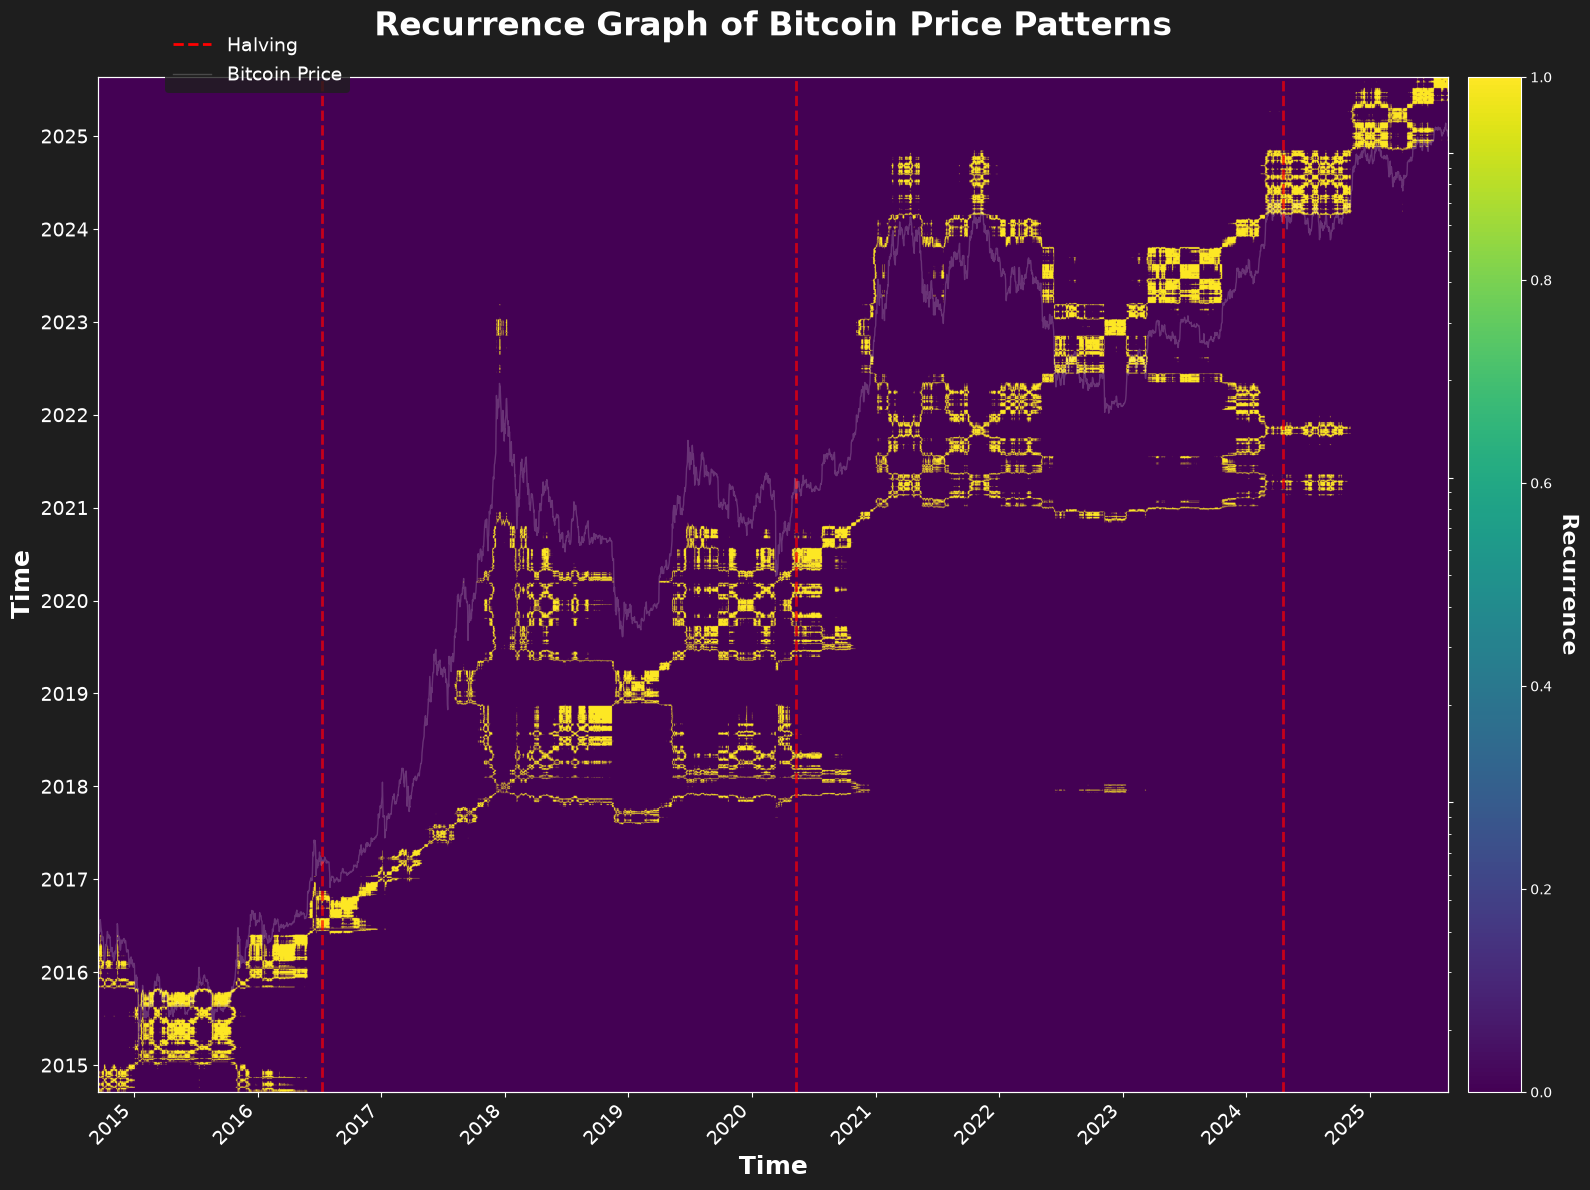

In [2]:
rp = RecurrencePlot(threshold="point", percentage=3, dimension=1)
# .copy(): numpy 2 отдаёт массив Close только для чтения,
# numba внутри pyts такой массив не принимает.
close = np.ascontiguousarray(np.log(btc_data["Close"].to_numpy(dtype=float)))
X_rp = rp.fit_transform(close.reshape(1, -1).copy())

plt.style.use("dark_background")

fig = plt.figure(figsize=(16, 12))
gs = GridSpec(1, 20, figure=fig)
ax1 = fig.add_subplot(gs[0, :19])
cax = fig.add_subplot(gs[0, 19])
ax2 = ax1.twinx()

im = ax1.imshow(
    X_rp[0],
    cmap="viridis",
    aspect="auto",
    extent=[
        mdates.date2num(btc_data.index[0]),
        mdates.date2num(btc_data.index[-1]),
        mdates.date2num(btc_data.index[0]),
        mdates.date2num(btc_data.index[-1]),
    ],
    origin="lower",
)

ax1.set_title(
    "Recurrence Graph of Bitcoin Price Patterns",
    fontsize=24,
    fontweight="bold",
    pad=30,
)
ax1.set_xlabel("Time", fontsize=18, fontweight="bold")
ax1.set_ylabel("Time", fontsize=18, fontweight="bold")

ax2.plot(btc_data.index, btc_data["Close"], color="white", alpha=0.2, linewidth=1)
ax2.tick_params(axis="y", labelcolor="white", labelsize=14)
ax2.set_yscale("log")
ax2.set_yticklabels([])

ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.xaxis.set_major_locator(mdates.YearLocator())
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=45, ha="right", fontsize=14)
# В старой ячейке год стоял только на X, ось Y оставалась числом matplotlib.
ax1.yaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.yaxis.set_major_locator(mdates.YearLocator())
plt.setp(ax1.yaxis.get_majorticklabels(), fontsize=14)

halving_dates = [
    datetime(2012, 11, 28),
    datetime(2016, 7, 9),
    datetime(2020, 5, 11),
    datetime(2024, 4, 20),
]
for date in halving_dates:
    if btc_data.index[0] <= date <= btc_data.index[-1]:
        ax1.axvline(x=mdates.date2num(date), color="red", linestyle="--", alpha=0.7, linewidth=2)

ax1.plot([], [], color="red", linestyle="--", label="Halving", linewidth=2)
ax2.plot([], [], color="white", label="Bitcoin Price", linewidth=1, alpha=0.2)
fig.legend(
    loc="upper left",
    bbox_to_anchor=(0.1, 0.98),
    fontsize=14,
    facecolor="#1E1E1E",
    edgecolor="none",
)

cbar = fig.colorbar(im, cax=cax)
cbar.set_label("Recurrence", rotation=270, labelpad=20, fontsize=16, fontweight="bold")

fig.patch.set_facecolor("#1E1E1E")
plt.tight_layout()

root = Path.cwd()
if not (root / "requirements.txt").exists():
    root = root.parent
out_dir = root / "output"
out_dir.mkdir(exist_ok=True)
out_path = out_dir / "bitcoin_recurrence_price_plot.png"
fig.savefig(out_path, dpi=300, bbox_inches="tight")
print(out_path)
plt.show()
